In [3]:
import pandas as pd
import sklearn
import nltk
import pdfplumber

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

print("All good!")

ModuleNotFoundError: No module named 'pdfplumber'

In [5]:
%pip install pdfplumber

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.6 MB/s eta 0:00:00
  Using cached pillow-12.3.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.1 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 11.5 MB/s eta 0:00:0000:0100:01
Using cached pillow-12.3.0-cp312-cp312-macosx_11_0_arm64.whl (4.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 5.7 MB/s eta 0:00:0000:0100:01m
  Attempting uninstall: Pillow
    Found existing installation: pillow 10.3.0
    Uninstalling pillow-10.3.0:
      Successfully uninstalled pillow-10.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.32.0 requires pillow<11,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
Note: you ma

In [1]:
%pip install "pillow<11"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 11.3 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pdfplumber 0.11.10 requires Pillow>=12.2.0, but you have pillow 10.4.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pdfplumber, os

def read_pdf(path):
    text = ""
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            text += (page.extract_text() or "") + "\n"
    return text

docs = []
for folder, doc_type in [("data/leases", "lease"), ("data/notices", "notice")]:
    for f in os.listdir(folder):
        if f.lower().endswith(".pdf"):
            text = read_pdf(os.path.join(folder, f))
            docs.append({"file": f, "type": doc_type, "text": text})
            print(f"{doc_type:7} | {f:40} | {len(text):6} characters")

FileNotFoundError: [Errno 2] No such file or directory: 'data/leases'

In [5]:
import os
print("Notebook is in:", os.getcwd())

# Search your home folder for the leases folder
home = os.path.expanduser("~")
for root, dirs, files in os.walk(home):
    if root.endswith(os.path.join("data", "leases")):
        print("Found leases folder at:", root)
    if root.count(os.sep) - home.count(os.sep) > 4:
        dirs[:] = []   # don't search too deep

Notebook is in: /Users/marufi


In [7]:
  os.chdir("/Users/yourname/lease-checker")   # replace with your path
  print(os.listdir("data"))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/yourname/lease-checker'

In [9]:
import os

project = os.path.expanduser("~/lease-checker")
os.makedirs(os.path.join(project, "data", "leases"), exist_ok=True)
os.makedirs(os.path.join(project, "data", "notices"), exist_ok=True)
os.chdir(project)

print("Notebook is now in:", os.getcwd())
print("Leases folder has:", os.listdir("data/leases"))
print("Notices folder has:", os.listdir("data/notices"))

Notebook is now in: /Users/marufi/lease-checker
Leases folder has: []
Notices folder has: []


In [11]:
import glob
for place in ["~/Downloads", "~/Desktop", "~/Documents"]:
    for f in glob.glob(os.path.expanduser(place + "/**/*.pdf"), recursive=True):
        print(f)

/Users/marufi/Downloads/Deep_Learning_Study_Assistant_Presentation.pdf
/Users/marufi/Downloads/Lecture 6- 7 signal-Processing.pdf
/Users/marufi/Downloads/lecture_5-6- Regularization and optimization.pdf
/Users/marufi/Downloads/종합소득세 원클릭 환급신고 주요 QA.pdf
/Users/marufi/Downloads/titanik dataset - Colab.pdf
/Users/marufi/Downloads/Crop_Fertilizer_Recommendation_Report.pdf
/Users/marufi/Downloads/LAB 1 - Colab.pdf
/Users/marufi/Downloads/Project3_Report.pdf
/Users/marufi/Downloads/smart_crop_fertilizer_recommendation_poster.pdf
/Users/marufi/Downloads/Lecture 2_image_formation2026.pdf
/Users/marufi/Downloads/ml_math_report.pdf
/Users/marufi/Downloads/medical insurance dataset - Colab.pdf
/Users/marufi/Downloads/Image_Pyramids_Filtering_Upsampling_Lab_Report.pdf
/Users/marufi/Downloads/supervised_learning_lab_assignment_completed.pdf
/Users/marufi/Downloads/Agro Final PR pdf.pdf
/Users/marufi/Downloads/crop_recommendation_project,ipynb - Colab.pdf
/Users/marufi/Download

In [13]:
import shutil

leases = [
    "/Users/marufi/Downloads/sample_lease_1.pdf",   # replace with your files
]
notices = [
    "/Users/marufi/Downloads/eviction_notice_1.pdf",  # replace with your files
]

for f in leases:
    shutil.copy(f, "data/leases")
for f in notices:
    shutil.copy(f, "data/notices")

print("Leases:", os.listdir("data/leases"))
print("Notices:", os.listdir("data/notices"))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/marufi/Downloads/sample_lease_1.pdf'

In [15]:
import glob, shutil

lease_words = ["lease", "rent", "tenan"]
notice_words = ["evict", "notice", "quit"]

found = 0
for place in ["~/Downloads", "~/Desktop", "~/Documents"]:
    for f in glob.glob(os.path.expanduser(place + "/**/*.pdf"), recursive=True):
        name = os.path.basename(f).lower()
        if any(w in name for w in notice_words):
            shutil.copy(f, "data/notices"); found += 1
        elif any(w in name for w in lease_words):
            shutil.copy(f, "data/leases"); found += 1

print("Copied", found, "files")
print("Leases:", os.listdir("data/leases"))
print("Notices:", os.listdir("data/notices"))

Copied 0 files
Leases: []
Notices: []


In [20]:
import pdfplumber, os

def read_pdf(path):
    text = ""
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            text += (page.extract_text() or "") + "\n"
    return text

docs = []
for folder, doc_type in [("data/leases", "lease"), ("data/notices", "notice")]:
    for f in os.listdir(folder):
        if f.lower().endswith(".pdf"):
            text = read_pdf(os.path.join(folder, f))
            docs.append({"file": f, "type": doc_type, "text": text})
            print(f"{doc_type:7} | {f:40} | {len(text):6} characters")

In [22]:
import os, glob, shutil

os.chdir(os.path.expanduser("~/lease-checker"))

lease_words = ["lease", "rent", "tenan"]
notice_words = ["evict", "notice", "quit"]

found = 0
for place in ["~/Downloads", "~/Desktop", "~/Documents"]:
    for f in glob.glob(os.path.expanduser(place + "/**/*.pdf"), recursive=True):
        if "lease-checker" in f:
            continue   # skip files already in the project
        name = os.path.basename(f).lower()
        if any(w in name for w in notice_words):
            shutil.copy(f, "data/notices"); found += 1
        elif any(w in name for w in lease_words):
            shutil.copy(f, "data/leases"); found += 1

print("Copied", found, "files")
print("Leases:", os.listdir("data/leases"))
print("Notices:", os.listdir("data/notices"))

Copied 9 files
Leases: ['pdf-1050g-sample_rental_agreement_basic_beginning_renting_an_apartment_or_house.pdf', 'Basic-Rental-Agreement-or-Residential-Lease.pdf', 'LEASE-AGREEMENT-RESIDENTIAL-October-2019.pdf', 'Simple-1-Page-Residential-Lease-Agreement.pdf', 'PennsylvaniaStandardResidentialLeaseAgreement.pdf', 'LEASE-AGREEMENT-RESIDENTIAL-October-2019-2.pdf']
Notices: ['Notice-to-Quit-Form.pdf', 'PRINTABLE-EVICTION-NOTICE-LETTER.pdf', 'Notice-Non-PaymentofRent.pdf']


In [24]:
import pdfplumber, os

def read_pdf(path):
    text = ""
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            text += (page.extract_text() or "") + "\n"
    return text

docs = []
for folder, doc_type in [("data/leases", "lease"), ("data/notices", "notice")]:
    for f in os.listdir(folder):
        if f.lower().endswith(".pdf"):
            text = read_pdf(os.path.join(folder, f))
            docs.append({"file": f, "type": doc_type, "text": text})
            print(f"{doc_type:7} | {f:40} | {len(text):6} characters")

lease   | pdf-1050g-sample_rental_agreement_basic_beginning_renting_an_apartment_or_house.pdf |   8195 characters
lease   | Basic-Rental-Agreement-or-Residential-Lease.pdf |  14451 characters
lease   | LEASE-AGREEMENT-RESIDENTIAL-October-2019.pdf |  21026 characters
lease   | Simple-1-Page-Residential-Lease-Agreement.pdf |   1501 characters
lease   | PennsylvaniaStandardResidentialLeaseAgreement.pdf |  23355 characters
lease   | LEASE-AGREEMENT-RESIDENTIAL-October-2019-2.pdf |  21026 characters
notice  | Notice-to-Quit-Form.pdf                  |      1 characters
notice  | PRINTABLE-EVICTION-NOTICE-LETTER.pdf     |    692 characters
notice  | Notice-Non-PaymentofRent.pdf             |    661 characters


In [26]:
import re
import pandas as pd

def split_clauses(text):
    # New clause starts at lines like "1.", "12)", "Section 3", "ARTICLE 4"
    pattern = r'\n(?=\s*(?:\d{1,2}[\.\)]\s|Section\s+\d|SECTION\s+\d|ARTICLE\s+\w))'
    parts = re.split(pattern, text)
    # If no numbering was found, split on blank lines instead
    if len(parts) < 3:
        parts = re.split(r'\n\s*\n', text)
    clauses = [" ".join(p.split()) for p in parts]
    return [c for c in clauses if len(c) > 40]   # drop tiny fragments

rows = []
for d in docs:
    for i, c in enumerate(split_clauses(d["text"])):
        rows.append({"file": d["file"], "type": d["type"], "clause_id": i, "clause": c})

clauses = pd.DataFrame(rows)
clauses.to_csv("data/clauses.csv", index=False)

print("Total clauses:", len(clauses))
print(clauses.groupby("file").size())
clauses.head(10)

Total clauses: 101
file
Basic-Rental-Agreement-or-Residential-Lease.pdf                                        34
LEASE-AGREEMENT-RESIDENTIAL-October-2019-2.pdf                                         19
LEASE-AGREEMENT-RESIDENTIAL-October-2019.pdf                                           19
Notice-Non-PaymentofRent.pdf                                                            1
PRINTABLE-EVICTION-NOTICE-LETTER.pdf                                                    1
PennsylvaniaStandardResidentialLeaseAgreement.pdf                                       6
Simple-1-Page-Residential-Lease-Agreement.pdf                                           6
pdf-1050g-sample_rental_agreement_basic_beginning_renting_an_apartment_or_house.pdf    15
dtype: int64


,file,type,clause_id,clause
0,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,0,SAMPLE RENTAL AGREEMENT (Basic / Beginning) TH...
1,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,1,1. FIXED-TERM AGREEMENT (LEASE): Tenants agree...
2,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,2,2. RENT: Tenant agrees to pay Landlord as base...
3,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,3,3. FORM OF PAYMENT: Tenants agree to pay their...
4,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,4,4. RENT PAYMENT PROCEDURE: Tenants agree to pa...
5,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,5,5. RENT DUE DATE: Tenant hereby acknowledges t...
6,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,6,6. BAD-CHECK SERVICING CHARGE: In the event Te...
7,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,7,7. SECURITY DEPOSIT: Tenants hereby agree to p...
8,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,8,8. CLEANING FEE Tenant hereby agrees to accept...
9,pdf-1050g-sample_rental_agreement_basic_beginn...,lease,9,9. REMOVAL OF LANDLORD’S PROPERTY: If anyone r...


In [28]:
from nltk.tokenize import sent_tokenize

# 1. Drop duplicate file
clauses = clauses[~clauses["file"].str.endswith("-2.pdf")]

# 2. Split notices into sentences
rows = []
for _, r in clauses.iterrows():
    if r["type"] == "notice":
        for s in sent_tokenize(r["clause"]):
            if len(s) > 40:
                rows.append({"file": r["file"], "type": "notice", "clause": s})
    else:
        rows.append({"file": r["file"], "type": r["type"], "clause": r["clause"]})

clauses = pd.DataFrame(rows).reset_index(drop=True)
clauses.to_csv("data/clauses.csv", index=False)

print("Total clauses:", len(clauses))
print(clauses.groupby(["type", "file"]).size())

LookupError: 
**********************************************************************
  Resource [93mpunkt[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt/PY3/english.pickle[0m

  Searched in:
    - '/Users/marufi/nltk_data'
    - '/opt/anaconda3/nltk_data'
    - '/opt/anaconda3/share/nltk_data'
    - '/opt/anaconda3/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
    - ''
**********************************************************************


In [30]:
import re

def split_sentences(text):
    # split after . ! ? when followed by a space and a capital letter
    return re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)

# 1. Drop duplicate file
clauses = clauses[~clauses["file"].str.endswith("-2.pdf")]

# 2. Split notices into sentences
rows = []
for _, r in clauses.iterrows():
    if r["type"] == "notice":
        for s in split_sentences(r["clause"]):
            if len(s) > 40:
                rows.append({"file": r["file"], "type": "notice", "clause": s})
    else:
        rows.append({"file": r["file"], "type": r["type"], "clause": r["clause"]})

clauses = pd.DataFrame(rows).reset_index(drop=True)
clauses.to_csv("data/clauses.csv", index=False)

print("Total clauses:", len(clauses))
print(clauses.groupby(["type", "file"]).size())

Total clauses: 90
type    file                                                                               
lease   Basic-Rental-Agreement-or-Residential-Lease.pdf                                        34
        LEASE-AGREEMENT-RESIDENTIAL-October-2019.pdf                                           19
        PennsylvaniaStandardResidentialLeaseAgreement.pdf                                       6
        Simple-1-Page-Residential-Lease-Agreement.pdf                                           6
        pdf-1050g-sample_rental_agreement_basic_beginning_renting_an_apartment_or_house.pdf    15
notice  Notice-Non-PaymentofRent.pdf                                                            4
        PRINTABLE-EVICTION-NOTICE-LETTER.pdf                                                    6
dtype: int64


import os

label_file = "data/labeled.csv"
if os.path.exists(label_file):
    labeled = pd.read_csv(label_file)
else:
    labeled = clauses.copy()
    labeled["label"] = None

todo = labeled[labeled["label"].isna()].index
print(f"{len(todo)} clauses left. Type 0 (normal), 1 (risky), s (skip), q (quit and save)\n")import os

label_file = "data/labeled.csv"
if os.path.exists(label_file):
    labeled = pd.read_csv(label_file)
else:
    labeled = clauses.copy()
    labeled["label"] = None

todo = labeled[labeled["label"].isna()].index
print(f"{len(todo)} clauses left. Type 0 (normal), 1 (risky), s (skip), q (quit and save)\n")

for i in todo:
    print("=" * 80)
    print(f"[{i}] {labeled.at[i, 'type'].upper()} - {labeled.at[i, 'file']}\n")
    print(labeled.at[i, "clause"][:800])
    ans = input("\nLabel: ").strip().lower()
    if ans == "q":
        break
    if ans in ("0", "1"):
        labeled.at[i, "label"] = int(ans)
    labeled.to_csv(label_file, index=False)   # saves after every answer

labeled.to_csv(label_file, index=False)
print("\nSaved. Labeled so far:", labeled["label"].notna().sum(), "of", len(labeled))
print(labeled["label"].value_counts())

for i in todo:
    print("=" * 80)
    print(f"[{i}] {labeled.at[i, 'type'].upper()} - {labeled.at[i, 'file']}\n")
    print(labeled.at[i, "clause"][:800])
    ans = input("\nLabel: ").strip().lower()
    if ans == "q":
        break
    if ans in ("0", "1"):
        labeled.at[i, "label"] = int(ans)
    labeled.to_csv(label_file, index=False)   # saves after every answer

labeled.to_csv(label_file, index=False)
print("\nSaved. Labeled so far:", labeled["label"].notna().sum(), "of", len(labeled))
print(labeled["label"].value_counts())

In [35]:
import os

label_file = "data/labeled.csv"
if os.path.exists(label_file):
    labeled = pd.read_csv(label_file)
else:
    labeled = clauses.copy()
    labeled["label"] = None

todo = labeled[labeled["label"].isna()].index
print(f"{len(todo)} clauses left. Type 0 (normal), 1 (risky), s (skip), q (quit and save)\n")

for i in todo:
    print("=" * 80)
    print(f"[{i}] {labeled.at[i, 'type'].upper()} - {labeled.at[i, 'file']}\n")
    print(labeled.at[i, "clause"][:800])
    ans = input("\nLabel: ").strip().lower()
    if ans == "q":
        break
    if ans in ("0", "1"):
        labeled.at[i, "label"] = int(ans)
    labeled.to_csv(label_file, index=False)   # saves after every answer

labeled.to_csv(label_file, index=False)
print("\nSaved. Labeled so far:", labeled["label"].notna().sum(), "of", len(labeled))
print(labeled["label"].value_counts())

3 clauses left. Type 0 (normal), 1 (risky), s (skip), q (quit and save)

[15] LEASE - Basic-Rental-Agreement-or-Residential-Lease.pdf

BASIC RENTAL AGREEMENT OR RESIDENTIAL LEASE This Rental Agreement or Residential Lease shall be evidence of the complete terms and conditions under which the parties whose signatures appear below have agreed. Landlord/Lessor/Agent, _________________________, shall be referred to as "OWNER" and Tenant(s)/Lessee, _____________________________, shall be referred to as "RESIDENT." As consideration for this agreement, OWNER agrees to rent/lease to RESIDENT and RESIDENT agrees to rent/lease from OWNER for use solely as a private residence, the premises located at ______________________________________________in the city of _______________________________.



Label:  1


[26] LEASE - Basic-Rental-Agreement-or-Residential-Lease.pdf

11. DESTRUCTION OF PREMISES: If the premises become totally or partially destroyed during the term of this Agreement so that RESIDENT'S use is seriously impaired, OWNER or RESIDENT may terminate this Agreement immediately upon three day written notice to the other.



Label:  DD


[89] NOTICE - Notice-Non-PaymentofRent.pdf

You may redeem your tenancy by full payment of said arrears within _____ days of receipt of this notice. ________________________________ Landlord



Label:  0



Saved. Labeled so far: 89 of 90
label
1.0    84
0.0     5
Name: count, dtype: int64


In [37]:
labeled = clauses.copy()
labeled["label"] = None
label_file = "data/labeled.csv"

print("n = NORMAL (fair, standard)   r = RISKY (unfair to tenant)   s = skip   q = quit\n")

for i in labeled.index:
    print("=" * 80)
    print(f"[{i}] {labeled.at[i, 'type'].upper()}\n")
    print(labeled.at[i, "clause"][:800])
    ans = input("\nn = normal, r = risky: ").strip().lower()
    if ans == "q":
        break
    if ans == "n":
        labeled.at[i, "label"] = 0
    elif ans == "r":
        labeled.at[i, "label"] = 1
    labeled.to_csv(label_file, index=False)

labeled.to_csv(label_file, index=False)
print("\nNormal (0) vs Risky (1):")
print(labeled["label"].value_counts())

n = NORMAL (fair, standard)   r = RISKY (unfair to tenant)   s = skip   q = quit

[0] LEASE

SAMPLE RENTAL AGREEMENT (Basic / Beginning) THIS AGREEMENT made this 15th Day of June, 2012, by and between ABC Properties, herein called “Landlord,” and Silvia Mando, herein called “Tenant.” Landlord hereby agrees to rent to Tenant the dwelling located at 9876 Cherry Avenue, Apartment 426 under the following terms and conditions.



n = normal, r = risky:  n


[1] LEASE

1. FIXED-TERM AGREEMENT (LEASE): Tenants agree to lease this dwelling for a fixed term of one year, beginning July 1, 2012 and ending June 30, 2013. Upon expiration, this Agreement shall become a month-to-month agreement AUTOMATICALLY, UNLESS either Tenants or Owners notify the other party in writing at least 30 days prior to expiration that they do not wish this Agreement to continue on any basis.



n = normal, r = risky:  n


[2] LEASE

2. RENT: Tenant agrees to pay Landlord as base rent the sum of $685 per month, due and payable monthly in advance on the 1st day of each month during the term of this agreement. The first month’s rent is required to be submitted on or before move-in.



n = normal, r = risky:  n


... (171 outputs left out)


n = normal, r = risky:  n


[89] NOTICE

You may redeem your tenancy by full payment of said arrears within _____ days of receipt of this notice. ________________________________ Landlord



n = normal, r = risky:  n



Normal (0) vs Risky (1):
label
0    90
Name: count, dtype: int64


In [39]:
risky = [
    # (category, clause)
    ("entry", "Landlord may enter the premises at any time, with or without notice, for any reason."),
    ("entry", "Owner reserves the right to inspect the unit at any hour without prior notice to Resident."),
    ("entry", "Tenant agrees that Landlord and its agents may enter the dwelling unannounced whenever Landlord deems necessary."),
    ("deposit", "The security deposit is non-refundable under all circumstances."),
    ("deposit", "Landlord may keep the entire security deposit for any reason at Landlord's sole discretion."),
    ("deposit", "Tenant forfeits the full deposit if Tenant moves out for any reason before the end of the term."),
    ("fees", "A late fee of $100 per day will be charged for every day rent is late, with no maximum."),
    ("fees", "If rent is one day late, Tenant shall pay a penalty equal to 50% of the monthly rent."),
    ("fees", "Tenant shall pay all of Landlord's attorney fees in any dispute, regardless of who wins."),
    ("fees", "Any returned check will result in a $500 charge and immediate termination of this lease."),
    ("repairs", "Tenant is responsible for all repairs to the premises, including roof, plumbing, heating and structural repairs."),
    ("repairs", "Tenant accepts the premises as-is and Landlord shall have no obligation to make any repairs during the term."),
    ("repairs", "Tenant shall pay for normal wear and tear, including full repainting and carpet replacement, at the end of the lease."),
    ("waiver", "Tenant waives all rights to notice before any eviction proceeding."),
    ("waiver", "Tenant waives the right to a jury trial and the right to appeal in any action arising from this lease."),
    ("waiver", "Tenant agrees not to report any building or health code violations to housing authorities."),
    ("waiver", "Tenant waives any right to withhold rent for any reason, including uninhabitable conditions."),
    ("liability", "Landlord shall not be liable for any injury or damage to Tenant or guests, even if caused by Landlord's negligence."),
    ("liability", "Tenant shall indemnify Landlord against all claims, including those resulting from Landlord's own fault."),
    ("lockout", "If rent is not paid on the due date, Landlord may change the locks and remove Tenant's belongings without a court order."),
    ("lockout", "Landlord may shut off water, electricity or heat if rent is late."),
    ("lockout", "Any belongings left in the unit after eviction become the property of Landlord and may be sold or destroyed immediately."),
    ("termination", "Landlord may terminate this lease at any time without cause by giving 24 hours notice."),
    ("termination", "If Tenant ends the lease early, Tenant must pay all remaining rent for the entire term plus a penalty of three months rent."),
    ("termination", "This lease automatically renews for another full year unless Tenant gives 180 days written notice."),
    ("rent_increase", "Landlord may increase the rent at any time during the lease term without notice."),
    ("rent_increase", "Rent may be raised by any amount Landlord chooses upon 7 days notice."),
    ("privacy", "Tenant may not have any overnight guests without written permission from Landlord."),
    ("privacy", "Landlord may install security cameras inside the unit at Landlord's discretion."),
    ("notice", "You must vacate the premises within 24 hours of this notice or your belongings will be removed."),
    ("notice", "Failure to pay within one day will result in immediate removal from the property without court proceedings."),
    ("notice", "By receiving this notice you give up your right to contest this eviction in court."),
]

extra = pd.DataFrame([{"file": "handwritten_risky", "type": "lease" if c != "notice" else "notice",
                       "clause": t, "label": 1, "category": cat} for cat, t in risky])

labeled = pd.read_csv("data/labeled.csv")
labeled = labeled[labeled["label"].notna()]
labeled["category"] = "normal"
data = pd.concat([labeled, extra], ignore_index=True)
data["label"] = data["label"].astype(int)
data.to_csv("data/dataset.csv", index=False)

print("Total:", len(data))
print(data["label"].value_counts())

Total: 122
label
0    90
1    32
Name: count, dtype: int64


In [41]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

data = pd.read_csv("data/dataset.csv")

def clean(text):
    text = text.lower()
    text = re.sub(r"_+", " ", text)          # remove blank form lines
    text = re.sub(r"[^a-z\s]", " ", text)     # keep letters only
    return " ".join(text.split())

data["clean"] = data["clause"].apply(clean)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

# 1. Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    data["clean"], data["label"], test_size=0.2, stratify=data["label"], random_state=42)

model.fit(X_train, y_train)
pred = model.predict(X_test)

print("=== Test set results ===")
print(classification_report(y_test, pred, target_names=["normal", "risky"]))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

# 2. 5-fold cross-validation (more reliable with small data)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, data["clean"], data["label"], cv=cv, scoring="f1")
print("\n5-fold F1 for 'risky':", scores.round(2), " mean =", round(scores.mean(), 2))

# 3. Words the model learned
model.fit(data["clean"], data["label"])
words = model.named_steps["tfidf"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
top = coefs.argsort()
print("\nTop RISKY words: ", list(words[top[-15:]][::-1]))
print("Top NORMAL words:", list(words[top[:15]]))

=== Test set results ===
              precision    recall  f1-score   support

      normal       0.90      1.00      0.95        18
       risky       1.00      0.71      0.83         7

    accuracy                           0.92        25
   macro avg       0.95      0.86      0.89        25
weighted avg       0.93      0.92      0.92        25

Confusion matrix:
 [[18  0]
 [ 2  5]]

5-fold F1 for 'risky': [0.25 0.83 0.67 0.67 0.6 ]  mean = 0.6

Top RISKY words:  ['landlord may', 'any', 'right to', 'without', 'landlord', 'may', 'notice', 'tenant shall', 'any reason', 'including', 'the unit', 'rent is', 'waives', 'tenant waives', 'if rent']
Top NORMAL words: ['agreement', 'of', 'and', 'the tenant', 'the landlord', 'this agreement', 'resident', 'or', 'shall be', 'on', 'rental', 'other', 'and or', 'be', 'to']


In [43]:
from sklearn.model_selection import cross_val_predict

# 1. Which clauses does the model get wrong? (each clause predicted while hidden from training)
probs = cross_val_predict(model, data["clean"], data["label"], cv=cv, method="predict_proba")[:, 1]
data["risk_prob"] = probs.round(2)

wrong = data[(data["risk_prob"] >= 0.5) != (data["label"] == 1)]
print(f"=== {len(wrong)} mistakes ===")
for _, r in wrong.iterrows():
    print(f"\ntrue={'RISKY' if r.label else 'normal'}  prob={r.risk_prob}")
    print(r.clause[:200])

# 2. Lower threshold: catch more risky clauses
for t in [0.5, 0.4, 0.3]:
    pred_t = (probs >= t).astype(int)
    print(f"\nThreshold {t}:")
    print(confusion_matrix(data["label"], pred_t))

# 3. Try your own clauses
model.fit(data["clean"], data["label"])
tests = [
    "Rent is due on the first day of each month.",
    "Landlord may enter the apartment whenever he wants without telling the tenant.",
    "The deposit will not be returned under any condition.",
    "Tenant shall keep the premises clean and sanitary.",
    "Landlord can raise the rent anytime.",
]
print("\n=== Your own clauses ===")
for t in tests:
    p = model.predict_proba([clean(t)])[0, 1]
    print(f"{p:.2f}  {'RISKY ⚠' if p >= 0.4 else 'ok'}  {t}")

=== 16 mistakes ===

true=normal  prob=0.51
Failure to do so will result in legal recourse & formal eviction proceedings in accordance with the state law.

true=RISKY  prob=0.46
Tenant agrees that Landlord and its agents may enter the dwelling unannounced whenever Landlord deems necessary.

true=RISKY  prob=0.45
The security deposit is non-refundable under all circumstances.

true=RISKY  prob=0.44
A late fee of $100 per day will be charged for every day rent is late, with no maximum.

true=RISKY  prob=0.45
Any returned check will result in a $500 charge and immediate termination of this lease.

true=RISKY  prob=0.42
Tenant is responsible for all repairs to the premises, including roof, plumbing, heating and structural repairs.

true=RISKY  prob=0.43
Tenant accepts the premises as-is and Landlord shall have no obligation to make any repairs during the term.

true=RISKY  prob=0.48
Tenant shall pay for normal wear and tear, including full repainting and carpet replacement, at the end of t

In [45]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(model, {"clf__C": [0.1, 1, 10, 100, 1000]}, cv=cv, scoring="f1")
grid.fit(data["clean"], data["label"])
print("Best C:", grid.best_params_["clf__C"], " CV F1:", round(grid.best_score_, 2))

best = grid.best_estimator_

# Re-check with the tuned model
probs = cross_val_predict(best, data["clean"], data["label"], cv=cv, method="predict_proba")[:, 1]
print("\nConfusion matrix (threshold 0.5):")
print(confusion_matrix(data["label"], (probs >= 0.5).astype(int)))
print(classification_report(data["label"], (probs >= 0.5).astype(int), target_names=["normal", "risky"]))

best.fit(data["clean"], data["label"])
print("=== Your own clauses ===")
for t in tests:
    p = best.predict_proba([clean(t)])[0, 1]
    print(f"{p:.2f}  {'RISKY ⚠' if p >= 0.5 else 'ok'}  {t}")

Best C: 10  CV F1: 0.64

Confusion matrix (threshold 0.5):
[[89  1]
 [16 16]]
              precision    recall  f1-score   support

      normal       0.85      0.99      0.91        90
       risky       0.94      0.50      0.65        32

    accuracy                           0.86       122
   macro avg       0.89      0.74      0.78       122
weighted avg       0.87      0.86      0.84       122

=== Your own clauses ===
0.25  ok  Rent is due on the first day of each month.
0.79  RISKY ⚠  Landlord may enter the apartment whenever he wants without telling the tenant.
0.39  ok  The deposit will not be returned under any condition.
0.42  ok  Tenant shall keep the premises clean and sanitary.
0.49  ok  Landlord can raise the rent anytime.


In [47]:
RULES = [
    ("Entry without notice",
     r"enter.*(without|with or without) (prior )?notice|enter.*(any time|anytime|any hour|whenever)|unannounced",
     "The landlord can come into your home without warning. Most places require reasonable notice (often 24 hours)."),
    ("Deposit may not be returned",
     r"non-?refundable|(keep|retain|forfeit)s?.*deposit|deposit.*not be returned",
     "You might lose your security deposit even if you did nothing wrong."),
    ("Very high fees or penalties",
     r"per day.*late|no maximum|penalty|\$\s?\d{3,}|attorney.?s? fees.*regardless",
     "This charges large or unlimited fees. Check if the amount is reasonable and legal where you live."),
    ("You pay for repairs",
     r"all repairs|as[- ]is|no obligation to (make )?(any )?repairs?|pay for normal wear",
     "You may have to pay for repairs that are normally the landlord's job, like plumbing, heating or normal wear."),
    ("You give up your rights",
     r"tenant waives|waives? (all|any|the) rights?|give up your right|not (to )?report",
     "You are asked to give up legal protections, such as notice, going to court, or reporting unsafe conditions."),
    ("Landlord avoids responsibility",
     r"not (be )?liable|indemnify|even if caused by",
     "The landlord says they are not responsible, even if they cause harm or damage."),
    ("Lockout or utility shutoff",
     r"change the locks|shut off|without (a )?court|sold or destroyed|remove.*belongings",
     "The landlord may lock you out, cut utilities, or take your things without going to court. This is illegal in many places."),
    ("Unfair ending or renewal",
     r"terminate.*without cause|remaining rent for the entire term|automatically renew",
     "The lease can end suddenly, trap you into renewing, or charge you heavily for leaving early."),
    ("Rent can rise anytime",
     r"(increase|raise)d?.{0,30}rent.{0,40}(any time|anytime|any amount|without notice)|rent.{0,20}(raised|increased).{0,20}any",
     "The landlord can raise your rent during the lease or without proper notice."),
    ("Privacy limits",
     r"cameras?.{0,30}inside|inside the unit.{0,30}cameras?|overnight guests",
     "This limits your privacy or who can visit your home."),
    ("Too little time to leave",
     r"within (24|48) hours|within one day|immediate removal",
     "You are given very little time to respond or move out. The law usually requires more notice."),
]

def check_clause(text, threshold=0.5):
    p = best.predict_proba([clean(text)])[0, 1]
    reasons = [(name, expl) for name, pat, expl in RULES if re.search(pat, text.lower())]
    risky = p >= threshold or len(reasons) > 0
    return risky, round(p, 2), reasons

# Evaluate model + rules together
rule_hit = data["clause"].apply(lambda t: any(re.search(pat, t.lower()) for _, pat, _ in RULES))
hybrid = ((probs >= 0.5) | rule_hit).astype(int)
print("=== Model + rules ===")
print(confusion_matrix(data["label"], hybrid))
print(classification_report(data["label"], hybrid, target_names=["normal", "risky"]))

print("Normal clauses wrongly flagged:")
for t in data[(hybrid == 1) & (data["label"] == 0)]["clause"]:
    print(" -", t[:150])

print("\n=== Your own clauses ===")
for t in tests:
    risky, p, reasons = check_clause(t)
    print(f"\n{'⚠ RISKY' if risky else '✓ ok'}  (model {p})  {t}")
    for name, expl in reasons:
        print(f"   → {name}: {expl}")

=== Model + rules ===
[[79 11]
 [ 0 32]]
              precision    recall  f1-score   support

      normal       1.00      0.88      0.93        90
       risky       0.74      1.00      0.85        32

    accuracy                           0.91       122
   macro avg       0.87      0.94      0.89       122
weighted avg       0.93      0.91      0.91       122

Normal clauses wrongly flagged:
 - 2. RENT: Tenant agrees to pay Landlord as base rent the sum of $685 per month, due and payable monthly in advance on the 1st day of each month during 
 - 5. RENT DUE DATE: Tenant hereby acknowledges that late payment will cause Landlord to incur costs not contemplated by this Rental Agreement. We allow 
 - 7. SECURITY DEPOSIT: Tenants hereby agree to pay a security deposit of $685 to be refunded upon vacating, returning the keys to the Landlord and termi
 - 8. CLEANING FEE Tenant hereby agrees to accept property in its present state of cleanliness. They agree to return the property in the s

In [49]:
fixes = {
    "Entry without notice":
        r"enter.{0,60}(without|with or without) (prior )?notice|enter.{0,40}(any time|anytime|any hour|whenever)(?!.{0,25}emergenc)|unannounced",
    "Deposit may not be returned":
        r"non-?refundable|(keep|retain|forfeit)s?.{0,15}(the )?(entire|full|whole) (security )?deposit|deposit.{0,30}(for any reason|not be returned)",
    "Very high fees or penalties":
        r"per day.{0,40}late|no maximum|\$\s?\d{3,}.{0,20}(charge|penalty)|attorney.?s? fees.{0,30}regardless|penalty equal to",
    "Unfair ending or renewal":
        r"terminate.{0,30}without cause|remaining rent for the entire term|automatically renews? for (another|a) (full )?year",
}
RULES = [(n, fixes.get(n, p), e) for n, p, e in RULES]

def fired(text):
    return [n for n, p, _ in RULES if re.search(p, text.lower())]

rule_hit = data["clause"].apply(lambda t: len(fired(t)) > 0)
hybrid = ((probs >= 0.5) | rule_hit).astype(int)
print(confusion_matrix(data["label"], hybrid))
print(classification_report(data["label"], hybrid, target_names=["normal", "risky"]))

print("Remaining false alarms:")
for i in data[(hybrid == 1) & (data["label"] == 0)].index:
    print(f" - [{', '.join(fired(data.clause[i])) or 'model ' + str(probs[i].round(2))}]  {data.clause[i][:120]}")

[[87  3]
 [ 0 32]]
              precision    recall  f1-score   support

      normal       1.00      0.97      0.98        90
       risky       0.91      1.00      0.96        32

    accuracy                           0.98       122
   macro avg       0.96      0.98      0.97       122
weighted avg       0.98      0.98      0.98       122

Remaining false alarms:
 - [You pay for repairs]  6. INCOMING/OUTGOING INSPECTIONS 6.1. The Landlord and Tenant must jointly inspect the Premises before the Tenant moves 
 - [You pay for repairs, Landlord avoids responsibility, Lockout or utility shutoff]  PENNSYLVANIA STANDARD LEASE AGREEMENT I. THE PARTIES. This Residential Lease Agreement (“Agreement”) made this _________
 - [model 0.54]  Failure to do so will result in legal recourse & formal eviction proceedings in accordance with the state law.


In [51]:
def check_document(pdf_path, doc_type="lease", threshold=0.5):
    text = read_pdf(pdf_path)
    parts = split_clauses(text)
    if doc_type == "notice":
        parts = [s for p in parts for s in split_sentences(p) if len(s) > 40]

    flagged = []
    for c in parts:
        risky, p, reasons = check_clause(c, threshold)
        if risky:
            flagged.append((c, p, reasons))

    print("=" * 80)
    print(f"REPORT: {os.path.basename(pdf_path)}")
    print(f"Clauses checked: {len(parts)}   |   Flagged: {len(flagged)}")
    print("=" * 80)
    if not flagged:
        print("✓ No risky clauses found.")
    for n, (c, p, reasons) in enumerate(flagged, 1):
        print(f"\n⚠ #{n}  (model risk score: {p})")
        print(f'  "{c[:300]}{"..." if len(c) > 300 else ""}"')
        if reasons:
            for name, expl in reasons:
                print(f"  → {name}: {expl}")
        else:
            print("  → The model finds this wording similar to unfair clauses. Read it carefully.")
    print("\nNote: This tool gives warnings, not legal advice. Check with a local tenant-rights office.")

# Try it on one lease and one notice
check_document("data/leases/Basic-Rental-Agreement-or-Residential-Lease.pdf", "lease")
check_document("data/notices/PRINTABLE-EVICTION-NOTICE-LETTER.pdf", "notice")

REPORT: Basic-Rental-Agreement-or-Residential-Lease.pdf
Clauses checked: 34   |   Flagged: 0
✓ No risky clauses found.

Note: This tool gives warnings, not legal advice. Check with a local tenant-rights office.
REPORT: PRINTABLE-EVICTION-NOTICE-LETTER.pdf
Clauses checked: 6   |   Flagged: 0
✓ No risky clauses found.

Note: This tool gives warnings, not legal advice. Check with a local tenant-rights office.


In [53]:
def check_text(text, title="Pasted text"):
    import tempfile
    parts = [p for p in split_clauses("\n" + text) if len(p) > 40]
    flagged = 0
    print("=" * 80); print(f"REPORT: {title}   |   Clauses: {len(parts)}"); print("=" * 80)
    for c in parts:
        risky, p, reasons = check_clause(c)
        mark = "⚠ RISKY" if risky else "✓ ok   "
        print(f"\n{mark} (model {p})  {c[:200]}")
        for name, expl in reasons:
            print(f"   → {name}: {expl}")
        flagged += risky
    print(f"\nFlagged {flagged} of {len(parts)} clauses.")

bad_lease = """
1. RENT: Tenant will pay $900 per month, due on the 5th day of each month.
2. ENTRY: The owner and his staff may come into the apartment at any hour, unannounced, to check on things.
3. DEPOSIT: The $900 deposit is non-refundable once the tenant has moved in.
4. UTILITIES: Tenant is responsible for paying electricity and internet bills.
5. MAINTENANCE: Tenant must fix all broken appliances, pipes and heating at their own cost.
6. LATE RENT: If rent is late, the landlord may shut off the electricity until payment is received.
7. PETS: No pets are allowed without the landlord's written approval.
8. DISPUTES: Tenant waives all rights to take the landlord to court.
9. NOISE: Tenant agrees to keep noise at a reasonable level after 10 pm.
"""
check_text(bad_lease, "Made-up unfair lease (test)")

REPORT: Made-up unfair lease (test)   |   Clauses: 9

✓ ok    (model 0.24)  1. RENT: Tenant will pay $900 per month, due on the 5th day of each month.

⚠ RISKY (model 0.42)  2. ENTRY: The owner and his staff may come into the apartment at any hour, unannounced, to check on things.
   → Entry without notice: The landlord can come into your home without warning. Most places require reasonable notice (often 24 hours).

⚠ RISKY (model 0.54)  3. DEPOSIT: The $900 deposit is non-refundable once the tenant has moved in.
   → Deposit may not be returned: You might lose your security deposit even if you did nothing wrong.

✓ ok    (model 0.44)  4. UTILITIES: Tenant is responsible for paying electricity and internet bills.

✓ ok    (model 0.42)  5. MAINTENANCE: Tenant must fix all broken appliances, pipes and heating at their own cost.

⚠ RISKY (model 0.8)  6. LATE RENT: If rent is late, the landlord may shut off the electricity until payment is received.
   → Lockout or utility shutoff: The lan

In [55]:
import joblib, json
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

os.makedirs("figures", exist_ok=True)

# 1. Save model + rules
joblib.dump(best, "lease_model.joblib")
json.dump(RULES, open("lease_rules.json", "w"), indent=2)

model_only = (probs >= 0.5).astype(int)

# Chart 1: Model only vs Model + rules (F1 for risky)
scores = {"TF-IDF + LR\n(model only)": f1_score(data["label"], model_only),
          "TF-IDF + LR\n+ rules (hybrid)": f1_score(data["label"], hybrid)}
plt.figure(figsize=(5, 4))
bars = plt.bar(scores.keys(), scores.values(), color=["#9aa5b1", "#2f6fdf"])
plt.bar_label(bars, fmt="%.2f")
plt.ylim(0, 1.05); plt.ylabel("F1 score (risky class)")
plt.title("Risky clause detection")
plt.tight_layout(); plt.savefig("figures/f1_comparison.png", dpi=150); plt.show()

# Chart 2: Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pred, title in [(axes[0], model_only, "Model only"), (axes[1], hybrid, "Model + rules")]:
    ConfusionMatrixDisplay.from_predictions(data["label"], pred, display_labels=["normal", "risky"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", dpi=150); plt.show()

# Chart 3: Top words the model learned
words = best.named_steps["tfidf"].get_feature_names_out()
coefs = best.named_steps["clf"].coef_[0]
idx = list(coefs.argsort()[:10]) + list(coefs.argsort()[-10:])
plt.figure(figsize=(7, 6))
plt.barh([words[i] for i in idx], [coefs[i] for i in idx],
         color=["#9aa5b1" if coefs[i] < 0 else "#d9534f" for i in idx])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("← normal          weight          risky →")
plt.title("W

SyntaxError: unterminated string literal (detected at line 40) (1279252751.py, line 40)

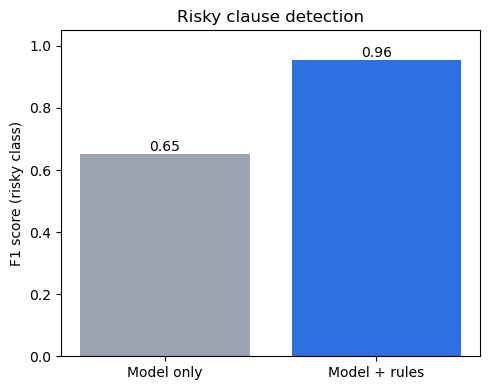

In [57]:
import joblib, json
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

os.makedirs("figures", exist_ok=True)
joblib.dump(best, "lease_model.joblib")
json.dump(RULES, open("lease_rules.json", "w"), indent=2)

model_only = (probs >= 0.5).astype(int)
scores = {"Model only": f1_score(data["label"], model_only),
          "Model + rules": f1_score(data["label"], hybrid)}

plt.figure(figsize=(5, 4))
bars = plt.bar(scores.keys(), scores.values(), color=["#9aa5b1", "#2f6fdf"])
plt.bar_label(bars, fmt="%.2f")
plt.ylim(0, 1.05)
plt.ylabel("F1 score (risky class)")
plt.title("Risky clause detection")
plt.tight_layout()
plt.savefig("figures/f1_comparison.png", dpi=150)
plt.show()

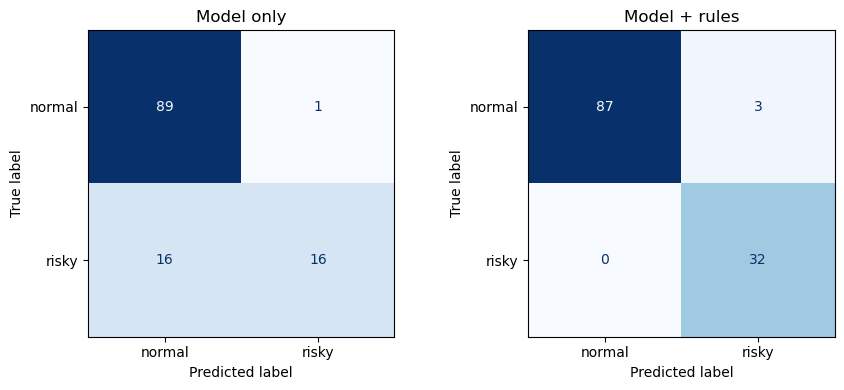

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_predictions(data["label"], model_only, display_labels=["normal", "risky"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Model only")
ConfusionMatrixDisplay.from_predictions(data["label"], hybrid, display_labels=["normal", "risky"],
                                        cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Model + rules")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()

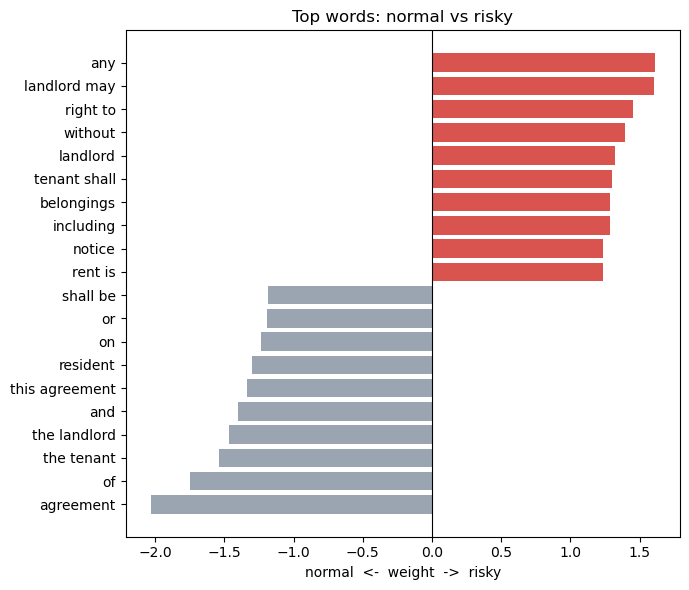

Saved model, rules and 3 charts.


In [61]:
words = best.named_steps["tfidf"].get_feature_names_out()
coefs = best.named_steps["clf"].coef_[0]
idx = list(coefs.argsort()[:10]) + list(coefs.argsort()[-10:])
colors = ["#9aa5b1" if coefs[i] < 0 else "#d9534f" for i in idx]

plt.figure(figsize=(7, 6))
plt.barh([words[i] for i in idx], [coefs[i] for i in idx], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("normal  <-  weight  ->  risky")
plt.title("Top words: normal vs risky")
plt.tight_layout()
plt.savefig("figures/top_words.png", dpi=150)
plt.show()
print("Saved model, rules and 3 charts.")

In [63]:
%%writefile ~/lease-checker/lease_checker.py
import os, re, json, joblib, pdfplumber

os.chdir(os.path.expanduser("~/lease-checker"))
best = joblib.load("lease_model.joblib")
...  (rest of the code, ending with print("Lease checker ready."))

Writing /Users/marufi/lease-checker/lease_checker.py


In [65]:
%%writefile ~/lease-checker/lease_checker.py
import os, re, json, joblib, pdfplumber

os.chdir(os.path.expanduser("~/lease-checker"))
best = joblib.load("lease_model.joblib")
RULES = json.load(open("lease_rules.json"))

def read_pdf(path):
    with pdfplumber.open(path) as pdf:
        return "\n".join((p.extract_text() or "") for p in pdf.pages)

def split_clauses(text):
    pattern = r'\n(?=\s*(?:\d{1,2}[\.\)]\s|Section\s+\d|SECTION\s+\d|ARTICLE\s+\w))'
    parts = re.split(pattern, text)
    if len(parts) < 3:
        parts = re.split(r'\n\s*\n', text)
    return [c for c in (" ".join(p.split()) for p in parts) if len(c) > 40]

def split_sentences(text):
    return re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)

def clean(text):
    text = re.sub(r"_+", " ", text.lower())
    return " ".join(re.sub(r"[^a-z\s]", " ", text).split())

def check_clause(text, threshold=0.5):
    p = best.predict_proba([clean(text)])[0, 1]
    reasons = [(n, e) for n, pat, e in RULES if re.search(pat, text.lower())]
    return (p >= threshold or len(reasons) > 0), round(p, 2), reasons

def report(parts, title):
    print("=" * 80)
    print(f"REPORT: {title}   |   Clauses checked: {len(parts)}")
    print("=" * 80)
    flagged = 0
    for c in parts:
        risky, p, reasons = check_clause(c)
        if risky:
            flagged += 1
            print(f'\n⚠ #{flagged} (model {p})  "{c[:300]}"')
            for n, e in reasons:
                print(f"   → {n}: {e}")
            if not reasons:
                print("   → Wording looks similar to unfair clauses. Read it carefully.")
    print(f"\nFlagged {flagged} of {len(parts)}." if flagged else "\n✓ No risky clauses found.")
    print("Note: This gives warnings, not legal advice.")

def check_document(path, doc_type="lease"):
    parts = split_clauses(read_pdf(path))
    if doc_type == "notice":
        parts = [s for p in parts for s in split_sentences(p) if len(s) > 40]
    report(parts, os.path.basename(path))

def check_text(text, title="Pasted text"):
    report(split_clauses("\n" + text), title)

print("Lease checker ready.")

Overwriting /Users/marufi/lease-checker/lease_checker.py


In [67]:
from sklearn.metrics import classification_report, confusion_matrix

# ---------- CHECK 1: Are all files in place? ----------
print("CHECK 1: Files")
for f in ["data/dataset.csv", "lease_model.joblib", "lease_rules.json", "lease_checker.py"]:
    print(f"  {'✓' if os.path.exists(f) else '✗ MISSING'}  {f}")

# ---------- CHECK 2: Does PDF reading work? ----------
print("\nCHECK 2: PDF reading")
pdf = os.path.join("data/leases", os.listdir("data/leases")[0])
n = len(split_clauses(read_pdf(pdf)))
print(f"  {'✓' if n > 0 else '✗'}  {os.path.basename(pdf)} → {n} clauses")

# ---------- CHECK 3: New clauses with known answers ----------
# 0 = normal, 1 = risky. New wording, never seen in training.
test_set = [
    (0, "The monthly rent is $1,200, payable on or before the first of each month."),
    (0, "Tenant shall not sublet the apartment without the landlord's written consent."),
    (0, "Landlord will give at least 24 hours written notice before entering, except in an emergency."),
    (0, "The security deposit will be returned within 30 days after move-out, minus documented damages."),
    (0, "Tenant is responsible for replacing light bulbs and smoke detector batteries."),
    (0, "Smoking is not permitted inside the unit."),
    (0, "Either party may end this month-to-month agreement with 30 days written notice."),
    (0, "Landlord is responsible for keeping heating, plumbing and electrical systems in good working order."),
    (0, "Tenant must keep the yard free of trash and debris."),
    (0, "Rent may be paid by check, money order, or bank transfer."),
    (1, "Management may access the unit whenever it wishes, without informing the occupant."),
    (1, "No part of the deposit will be given back at the end of the tenancy."),
    (1, "Rent paid after the 1st incurs a $75 charge for each day it is late."),
    (1, "The tenant must cover the cost of every repair, including the furnace and water heater."),
    (1, "Resident gives up the right to sue the owner for any reason."),
    (1, "The owner is not responsible for any harm on the property, even when the owner was careless."),
    (1, "If payment is missed, management may remove the tenant's possessions and change the door codes."),
    (1, "The landlord can cancel this agreement whenever he likes with one day of warning."),
    (1, "Rent can be increased at the owner's discretion during the lease period."),
    (1, "Tenant must vacate within 48 hours of receiving this letter."),
]

print("\nCHECK 3: New test clauses")
y_true, y_pred = [], []
for label, text in test_set:
    risky, p, reasons = check_clause(text)
    y_true.append(label); y_pred.append(int(risky))
    ok = "✓" if int(risky) == label else "✗ WRONG"
    print(f"  {ok:8} expected={'risky ' if label else 'normal'} got={'risky ' if risky else 'normal'} ({p})  {text[:70]}")

print("\n", confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["normal", "risky"]))

CHECK 1: Files
  ✓  data/dataset.csv
  ✓  lease_model.joblib
  ✓  lease_rules.json
  ✓  lease_checker.py

CHECK 2: PDF reading
  ✓  pdf-1050g-sample_rental_agreement_basic_beginning_renting_an_apartment_or_house.pdf → 15 clauses

CHECK 3: New test clauses
  ✓        expected=normal got=normal (0.27)  The monthly rent is $1,200, payable on or before the first of each mon
  ✓        expected=normal got=normal (0.42)  Tenant shall not sublet the apartment without the landlord's written c
  ✓        expected=normal got=normal (0.49)  Landlord will give at least 24 hours written notice before entering, e
  ✓        expected=normal got=normal (0.4)  The security deposit will be returned within 30 days after move-out, m
  ✓        expected=normal got=normal (0.43)  Tenant is responsible for replacing light bulbs and smoke detector bat
  ✗ WRONG  expected=normal got=risky  (0.67)  Smoking is not permitted inside the unit.
  ✓        expected=normal got=normal (0.29)  Either party may end this 

In [69]:
%pip install sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 4.5 MB/s eta 0:00:00
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 10.8 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 11.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 11.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 11.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 11.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 293.6/293.6 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 484.6/484.6 kB 10.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.3/123.3 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 10.1 MB/s eta 0:0

In [71]:
import pandas as pd, numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

encoder = SentenceTransformer("all-MiniLM-L6-v2")   # small model, works on CPU

data = pd.read_csv("data/dataset.csv")
X = encoder.encode(data["clause"].tolist(), normalize_embeddings=True)
y = data["label"].values

emb_clf = LogisticRegression(class_weight="balanced", C=10, max_iter=1000)

# Cross-validation on your dataset
cv = StratifiedKFold(5, shuffle=True, random_state=42)
p_cv = cross_val_predict(emb_clf, X, y, cv=cv, method="predict_proba")[:, 1]
print("=== Embeddings: cross-validation on dataset ===")
print(classification_report(y, (p_cv >= 0.5).astype(int), target_names=["normal", "risky"]))

# Train on all data, then test on the 20 new clauses
emb_clf.fit(X, y)
texts  = [t for _, t in test_set]
y_test = [l for l, _ in test_set]
p_new  = emb_clf.predict_proba(encoder.encode(texts, normalize_embeddings=True))[:, 1]

rule_hits = [any(re.search(pat, t.lower()) for _, pat, _ in RULES) for t in texts]
emb_only   = (p_new >= 0.5).astype(int)
emb_rules  = ((p_new >= 0.5) | np.array(rule_hits)).astype(int)

print("=== New 20 clauses ===")
for name, pred in [("TF-IDF + rules (old)", y_pred), ("Embeddings only", emb_only), ("Embeddings + rules", emb_rules)]:
    acc = (np.array(pred) == np.array(y_test)).mean()
    print(f"\n{name}: accuracy {acc:.0%}")
    print(confusion_matrix(y_test, pred))

print("\nPer clause (embeddings + rules):")
for t, l, p, pr in zip(texts, y_test, p_new, emb_rules):
    print(f"  {'✓' if pr == l else '✗'}  {p:.2f}  {t[:70]}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

=== Embeddings: cross-validation on dataset ===
              precision    recall  f1-score   support

      normal       0.95      0.97      0.96        90
       risky       0.90      0.84      0.87        32

    accuracy                           0.93       122
   macro avg       0.92      0.91      0.91       122
weighted avg       0.93      0.93      0.93       122

=== New 20 clauses ===

TF-IDF + rules (old): accuracy 60%
[[9 1]
 [7 3]]

Embeddings only: accuracy 65%
[[ 3  7]
 [ 0 10]]

Embeddings + rules: accuracy 65%
[[ 3  7]
 [ 0 10]]

Per clause (embeddings + rules):
  ✓  0.46  The monthly rent is $1,200, payable on or before the first of each mon
  ✗  0.83  Tenant shall not sublet the apartment without the landlord's written c
  ✗  0.86  Landlord will give at least 24 hours written notice before entering, e
  ✗  0.73  The security deposit will be returned within 30 days after move-out, m
  ✗  0.79  Tenant is responsible for replacing light bulbs and smoke detector bat
  ✗ 

In [73]:
normal_extra = [
    "Landlord may enter the unit to make repairs after giving the tenant reasonable advance notice.",
    "Owner will schedule inspections with the resident at a mutually agreed time.",
    "In an emergency such as fire or flooding, the landlord may enter immediately.",
    "The landlord must give written notice at least one day before showing the unit to new renters.",
    "The deposit will be refunded in full if the unit is returned in the same condition, except for normal wear and tear.",
    "Landlord will provide an itemized list of any deductions from the security deposit.",
    "The security deposit is held in a separate account and returned after the tenant moves out.",
    "Deductions from the deposit may only be made for unpaid rent or damage beyond normal wear.",
    "A late fee of $25 applies if rent is more than five days late.",
    "Tenant will be charged a reasonable fee for any check returned by the bank.",
    "There is no charge for paying rent online.",
    "Each party will pay its own legal costs unless a court decides otherwise.",
    "Landlord will repair broken appliances provided with the unit within a reasonable time.",
    "Tenant should report any leaks or damage to the landlord promptly.",
    "Tenant will pay for damage caused by the tenant's own carelessness or by their guests.",
    "The landlord is responsible for major repairs to the roof, walls and plumbing.",
    "Tenant agrees to change the air filter every three months.",
    "Nothing in this agreement limits the tenant's rights under local housing law.",
    "Either party may take a dispute to the local court or a mediation service.",
    "Tenant may contact the housing authority about unsafe conditions at any time.",
    "Tenant may request repairs in writing and keep a copy for their records.",
    "Tenant is encouraged to buy renter's insurance to protect personal belongings.",
    "Landlord is responsible for injuries caused by a failure to maintain common areas.",
    "Each party is responsible for damage caused by their own negligence.",
    "If rent is unpaid, the landlord must follow the legal eviction process through the courts.",
    "Tenant may end the lease early by giving 60 days notice and paying a fee of one month's rent.",
    "At the end of the lease, the agreement continues month to month unless either party gives 30 days notice.",
    "Landlord may end the tenancy only for reasons allowed by law, with proper written notice.",
    "Rent will stay the same for the full term of this lease.",
    "Any rent increase after the lease ends requires at least 60 days written notice.",
    "The rent amount will be reviewed once a year at renewal.",
    "Guests may stay up to fourteen days without needing landlord approval.",
    "Tenant may not change the locks without giving the landlord a copy of the new key.",
    "Pets are allowed with a signed pet agreement.",
    "Quiet hours are from 11 pm to 7 am.",
    "Tenant may hang pictures on the walls using small nails.",
    "Parking is available in the assigned space only.",
    "Trash must be placed in the bins provided by the building.",
    "This notice gives you 14 days to pay the overdue rent before the landlord applies to court.",
    "You have the right to dispute this notice in court.",
    "If you pay the full amount within the notice period, your tenancy will continue.",
]

extra = pd.DataFrame([{"file": "handwritten_normal", "type": "notice" if "notice" in t.lower() and "you" in t.lower() else "lease",
                       "clause": t, "label": 0, "category": "normal"} for t in normal_extra])
data = pd.concat([pd.read_csv("data/dataset.csv"), extra]).drop_duplicates("clause", ignore_index=True)
data.to_csv("data/dataset.csv", index=False)
print("Dataset now:", len(data), "clauses"); print(data["label"].value_counts())

Dataset now: 163 clauses
label
0    131
1     32
Name: count, dtype: int64


In [75]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

y = data["label"].values

# Retrain TF-IDF model
tfidf_model = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])
grid = GridSearchCV(tfidf_model, {"clf__C": [1, 10, 100]}, cv=cv, scoring="f1")
grid.fit(data["clause"].apply(clean), y)
tfidf_model = grid.best_estimator_

# Retrain embeddings model
X = encoder.encode(data["clause"].tolist(), normalize_embeddings=True)
emb_clf.fit(X, y)

# Test on the 20 new clauses
p_tfidf = tfidf_model.predict_proba([clean(t) for t in texts])[:, 1]
p_emb   = emb_clf.predict_proba(encoder.encode(texts, normalize_embeddings=True))[:, 1]
p_avg   = (p_tfidf + p_emb) / 2
rules_arr = np.array(rule_hits)

results = {
    "TF-IDF + rules":        ((p_tfidf >= 0.5) | rules_arr).astype(int),
    "Embeddings":            (p_emb >= 0.5).astype(int),
    "Embeddings + rules":    ((p_emb >= 0.5) | rules_arr).astype(int),
    "Average both + rules":  ((p_avg >= 0.5) | rules_arr).astype(int),
}
print(f"{'Method':24} Accuracy  Normal OK  Risky caught")
for name, pred in results.items():
    pred, yt = np.array(pred), np.array(y_test)
    print(f"{name:24} {(pred == yt).mean():6.0%}    {((pred == 0) & (yt == 0)).sum()}/10       {((pred == 1) & (yt == 1)).sum()}/10")

print("\nPer clause (Embeddings + rules):")
for t, l, p, pr in zip(texts, y_test, p_emb, results["Embeddings + rules"]):
    print(f"  {'✓' if pr == l else '✗'}  {p:.2f}  {t[:70]}")

Method                   Accuracy  Normal OK  Risky caught
TF-IDF + rules              60%    10/10       2/10
Embeddings                  75%    8/10       7/10
Embeddings + rules          80%    8/10       8/10
Average both + rules        60%    8/10       4/10

Per clause (Embeddings + rules):
  ✓  0.11  The monthly rent is $1,200, payable on or before the first of each mon
  ✗  0.79  Tenant shall not sublet the apartment without the landlord's written c
  ✓  0.41  Landlord will give at least 24 hours written notice before entering, e
  ✓  0.35  The security deposit will be returned within 30 days after move-out, m
  ✓  0.34  Tenant is responsible for replacing light bulbs and smoke detector bat
  ✗  0.56  Smoking is not permitted inside the unit.
  ✓  0.01  Either party may end this month-to-month agreement with 30 days writte
  ✓  0.48  Landlord is responsible for keeping heating, plumbing and electrical s
  ✓  0.34  Tenant must keep the yard free of trash and debris.
  ✓  0.14  R

In [77]:
joblib.dump(emb_clf, "lease_emb_model.joblib")
print("Saved lease_emb_model.joblib")

Saved lease_emb_model.joblib


In [79]:
%%writefile ~/lease-checker/lease_checker.py
import os, re, json, joblib, pdfplumber
from sentence_transformers import SentenceTransformer

os.chdir(os.path.expanduser("~/lease-checker"))
encoder = SentenceTransformer("all-MiniLM-L6-v2")
emb_model = joblib.load("lease_emb_model.joblib")
RULES = json.load(open("lease_rules.json"))

def read_pdf(path):
    with pdfplumber.open(path) as pdf:
        return "\n".join((p.extract_text() or "") for p in pdf.pages)

def split_clauses(text):
    pattern = r'\n(?=\s*(?:\d{1,2}[\.\)]\s|Section\s+\d|SECTION\s+\d|ARTICLE\s+\w))'
    parts = re.split(pattern, text)
    if len(parts) < 3:
        parts = re.split(r'\n\s*\n', text)
    return [c for c in (" ".join(p.split()) for p in parts) if len(c) > 40]

def split_sentences(text):
    return re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)

def check_clause(text, threshold=0.5):
    p = emb_model.predict_proba(encoder.encode([text], normalize_embeddings=True))[0, 1]
    reasons = [(n, e) for n, pat, e in RULES if re.search(pat, text.lower())]
    return (p >= threshold or len(reasons) > 0), round(float(p), 2), reasons

def report(parts, title):
    print("=" * 80)
    print(f"REPORT: {title}   |   Clauses checked: {len(parts)}")
    print("=" * 80)
    flagged = 0
    for c in parts:
        risky, p, reasons = check_clause(c)
        if risky:
            flagged += 1
            print(f'\n⚠ #{flagged} (model {p})  "{c[:300]}"')
            for n, e in reasons:
                print(f"   → {n}: {e}")
            if not reasons:
                print("   → The meaning is similar to unfair clauses. Read it carefully.")
    print(f"\nFlagged {flagged} of {len(parts)}." if flagged else "\n✓ No risky clauses found.")
    print("Note: This gives warnings, not legal advice.")

def check_document(path, doc_type="lease"):
    parts = split_clauses(read_pdf(path))
    if doc_type == "notice":
        parts = [s for p in parts for s in split_sentences(p) if len(s) > 40]
    report(parts, os.path.basename(path))

def check_text(text, title="Pasted text"):
    report(split_clauses("\n" + text), title)

print("Lease checker ready (embeddings + rules).")

Overwriting /Users/marufi/lease-checker/lease_checker.py


In [1]:
%run ~/lease-checker/lease_checker.py
check_text("""
1. Rent is due on the first day of each month.
2. Management may access the unit whenever it wishes, without informing the occupant.
""", "Quick test")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Lease checker ready (embeddings + rules).
REPORT: Quick test   |   Clauses checked: 2

✓ No risky clauses found.
Note: This gives warnings, not legal advice.


In [3]:
import pandas as pd, numpy as np
from sklearn.linear_model import LogisticRegression

PREFIX = r"^\s*(?:\d{1,2}(?:\.\d+)*[\.\)]?\s+)?(?:[A-Z][A-Z\s/&'\-]{2,}[:\.]\s*)?"
def strip_prefix(t):
    return re.sub(PREFIX, "", t).strip() or t

data = pd.read_csv("data/dataset.csv")
X = encoder.encode([strip_prefix(t) for t in data["clause"]], normalize_embeddings=True)
emb_model = LogisticRegression(class_weight="balanced", C=10, max_iter=1000).fit(X, data["label"])
joblib.dump(emb_model, "lease_emb_model.joblib")

for t in ["2. Management may access the unit whenever it wishes, without informing the occupant.",
          "Management may access the unit whenever it wishes, without informing the occupant.",
          "5. RENT DUE DATE: Rent is due on the first day of each month."]:
    s = strip_prefix(t)
    p = emb_model.predict_proba(encoder.encode([s], normalize_embeddings=True))[0, 1]
    print(f"{p:.2f}  {s}")

0.79  Management may access the unit whenever it wishes, without informing the occupant.
0.79  Management may access the unit whenever it wishes, without informing the occupant.
0.22  Rent is due on the first day of each month.


In [5]:
path = os.path.expanduser("~/lease-checker/lease_checker.py")
src = open(path).read()
if "strip_prefix" not in src:
    src = src.replace(
        "def check_clause(text, threshold=0.5):\n    p = emb_model.predict_proba(encoder.encode([text],",
        "PREFIX = r\"^\\s*(?:\\d{1,2}(?:\\.\\d+)*[\\.\\)]?\\s+)?(?:[A-Z][A-Z\\s/&'\\-]{2,}[:\\.]\\s*)?\"\n\n"
        "def strip_prefix(t):\n    return re.sub(PREFIX, '', t).strip() or t\n\n"
        "def check_clause(text, threshold=0.5):\n    p = emb_model.predict_proba(encoder.encode([strip_prefix(text)],")
    open(path, "w").write(src)
print("Updated ✓" if "strip_prefix" in open(path).read() else "✗ Not updated, tell me")

Updated ✓


In [1]:
%run ~/lease-checker/lease_checker.py
check_text("""
1. Rent is due on the first day of each month.
2. Management may access the unit whenever it wishes, without informing the occupant.
""", "Quick test")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Lease checker ready (embeddings + rules).
REPORT: Quick test   |   Clauses checked: 2

⚠ #1 (model 0.79)  "2. Management may access the unit whenever it wishes, without informing the occupant."
   → The meaning is similar to unfair clauses. Read it carefully.

Flagged 1 of 2.
Note: This gives warnings, not legal advice.


In [3]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

final_test = [
    (0, "3. UTILITIES: Tenant pays for gas and electricity; landlord pays for water."),
    (0, "Tenant may paint the bedroom walls with the landlord's approval."),
    (0, "The landlord will fix any heating problem within 48 hours of being told."),
    (0, "Rent receipts will be provided on request."),
    (0, "7. KEYS: Tenant will receive two keys and must return them when moving out."),
    (0, "The landlord will return the deposit with interest as required by state law."),
    (0, "Tenant may have a small vegetable garden in the backyard."),
    (0, "Landlord must give 30 days notice before any change to the house rules."),
    (0, "Tenant may break the lease without penalty if called to active military duty."),
    (0, "Bicycles may be stored in the basement storage room."),
    (1, "4. ACCESS: The property manager keeps a key and may let himself in day or night."),
    (1, "The tenant agrees to forfeit the deposit if the lease is not renewed."),
    (1, "Resident shall pay a $50 fee every time a maintenance request is made."),
    (1, "All appliance breakdowns are the renter's problem to fix and pay for."),
    (1, "The renter may not join or organize any tenant association."),
    (1, "Owner bears no responsibility for theft, flooding or mold, regardless of cause."),
    (1, "If rent is three days late, the owner may enter and take the tenant's furniture as payment."),
    (1, "The landlord may end this lease with 3 days notice if he decides to sell the house."),
    (1, "Rent will increase by 20 percent every three months."),
    (1, "Any complaint must be settled by an arbitrator chosen by the landlord, and the tenant gives up going to court."),
]

rows = []
for label, text in final_test:
    risky, p, reasons = check_clause(text)
    rows.append({"clause": text, "expected": label, "predicted": int(risky), "model_score": p,
                 "rule": ", ".join(n for n, _ in reasons), "correct": int(risky) == label})
    print(f"{'✓' if int(risky) == label else '✗'}  exp={'risky ' if label else 'normal'}  "
          f"got={'risky ' if risky else 'normal'}  {p:.2f}  {text[:65]}")

res = pd.DataFrame(rows)
res.to_csv("final_test_results.csv", index=False)
print("\n", confusion_matrix(res["expected"], res["predicted"]))
print(classification_report(res["expected"], res["predicted"], target_names=["normal", "risky"]))
print("Saved final_test_results.csv")

✓  exp=normal  got=normal  0.20  3. UTILITIES: Tenant pays for gas and electricity; landlord pays 
✓  exp=normal  got=normal  0.13  Tenant may paint the bedroom walls with the landlord's approval.
✗  exp=normal  got=risky   0.60  The landlord will fix any heating problem within 48 hours of bein
✓  exp=normal  got=normal  0.03  Rent receipts will be provided on request.
✓  exp=normal  got=normal  0.36  7. KEYS: Tenant will receive two keys and must return them when m
✓  exp=normal  got=normal  0.14  The landlord will return the deposit with interest as required by
✓  exp=normal  got=normal  0.10  Tenant may have a small vegetable garden in the backyard.
✓  exp=normal  got=normal  0.32  Landlord must give 30 days notice before any change to the house 
✗  exp=normal  got=risky   0.83  Tenant may break the lease without penalty if called to active mi
✓  exp=normal  got=normal  0.11  Bicycles may be stored in the basement storage room.
✓  exp=risky   got=risky   0.58  4. ACCESS: The propert

In [7]:
%run ~/lease-checker/lease_checker.py

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Lease checker ready (embeddings + rules).


In [9]:
check_document("check.pdf", "lease")

FileNotFoundError: [Errno 2] No such file or directory: 'check.pdf'

In [11]:
check_document(os.path.expanduser("~/check.pdf"), "lease")

PdfminerException: No /Root object! - Is this really a PDF?

In [13]:
with open(os.path.expanduser("~/check.pdf"), "rb") as f:
    start = f.read(200)
print(start)

b'PK\x03\x04\x14\x00\x06\x00\x08\x00\x00\x00!\x00\x83JK\xcd\x92\x01\x00\x00\xe1\x07\x00\x00\x13\x00\x08\x02[Content_Types].xml \xa2\x04\x02(\xa0\x00\x02\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'


In [15]:
%pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 8.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [17]:
import shutil
from docx import Document

# Make a correctly named copy
src = os.path.expanduser("~/check.pdf")
dst = os.path.expanduser("~/check.docx")
shutil.copy(src, dst)

def check_docx(path, title=None):
    doc = Document(path)
    paras = [" ".join(p.text.split()) for p in doc.paragraphs]
    # also read text inside tables
    for table in doc.tables:
        for row in table.rows:
            for cell in row.cells:
                paras.append(" ".join(cell.text.split()))
    parts = [p for p in dict.fromkeys(paras) if len(p) > 40]   # each paragraph = one clause
    report(parts, title or os.path.basename(path))

check_docx(dst)

REPORT: check.docx   |   Clauses checked: 71

⚠ #1 (model 0.51)  "Landlord willingly accepts new Rent from Tenant, which does not constitute past due Rent."
   → The meaning is similar to unfair clauses. Read it carefully.

⚠ #2 (model 0.67)  "(7.) The removal of unauthorized locks or fixtures installed by Tenant;"
   → The meaning is similar to unfair clauses. Read it carefully.

⚠ #3 (model 0.51)  "If deductions exceed the Security Deposit, Tenant will pay Landlord the excess amount within ten (10) days after Landlord makes written demand. The Security Deposit will be applied first to any non-rent items, including late charges, returned check charges, repairs, brokerage fees, and periodic util"
   → The meaning is similar to unfair clauses. Read it carefully.

⚠ #4 (model 0.53)  "8. ALTERATIONS AND IMPROVEMENTS. Tenant shall make no alterations to the buildings or improvements on the Property or construct any building or make any other improvements on the Property without the prior w